# 06 — Colour histograms + KNN / SVM / Random Forest

Third descriptor from the course (slides 122-125): the **colour histogram**: for each colour, how many pixels of the image have it.
It is the simplest descriptor: it ignores shape (HOG) and texture (LBP), and only counts colours.

We test the two colour spaces of the course:
- **RGB**: red, green, blue;
- **HSV**: **H**ue (the colour itself), **S**aturation (how vivid), **V**alue (how bright). HSV separates the colour from the lighting.

Everything else is **identical** to notebooks 04 and 05 (same crops, same 5 video groups, same video decision).

In [1]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") / "data" / "raw" / "urfd"
PROC = Path("..") / "data" / "processed"
PHASES = {-1: "not lying", 0: "falling", 1: "lying"}

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]

z = np.load(PROC / "crops64.npz")          # the 64 x 64 person crops made in notebook 04
frames = pd.DataFrame({"video": z["video"], "frame": z["frame"]}).merge(labels, on=["video", "frame"], how="left")
keep = frames.frame_label.notna().to_numpy()
crops, frames = z["crops"][keep], frames[keep].reset_index(drop=True)
frames["phase"] = frames.frame_label.map(PHASES)
y = frames.frame_label.astype(int).to_numpy()
print(crops.shape)
print(f"always answering 'not lying' would already give {np.mean(y == -1):.3f} accuracy")

(11027, 64, 64, 3)
always answering 'not lying' would already give 0.640 accuracy


💡 **Interpretation:** the same **11,027 colour crops** as notebooks 04-05. Reference point: always answering *not lying* already gives **0.640**, so a descriptor must clearly beat that to be useful.

## Step 1 — What a colour histogram looks like

Each channel's values (0-255) are grouped into a few **bins**. We count the pixels of the crop in each bin, then divide by the number of pixels so the histogram adds up to 1 (it does not depend on the image size).

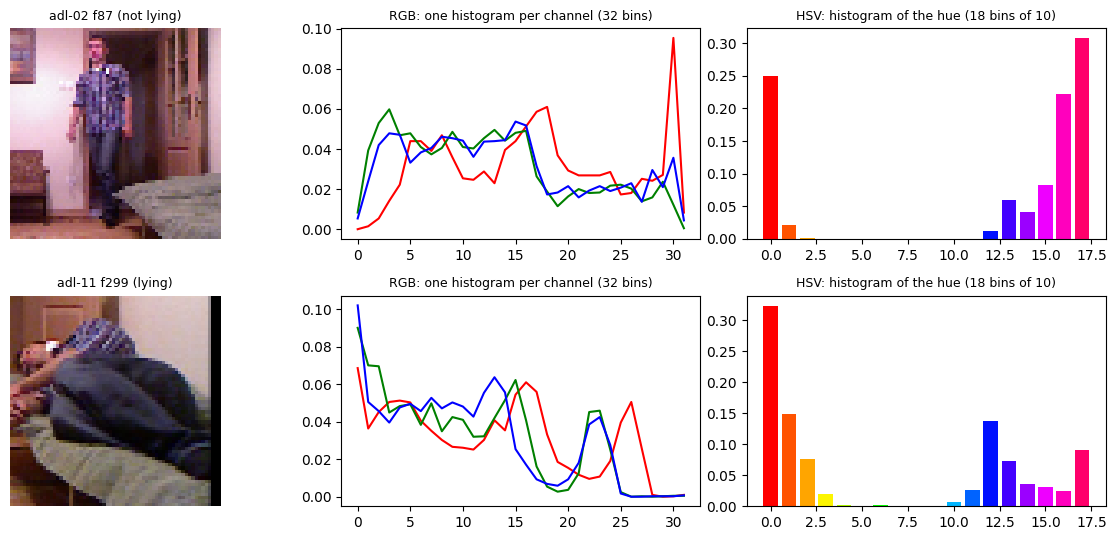

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
hsv_names = ["hue (0-179)", "saturation", "value (brightness)"]
for row, phase in zip(axes, ["not lying", "lying"]):
    i = frames[frames.phase == phase].index[200]
    row[0].imshow(crops[i]); row[0].axis("off"); row[0].set_title(f"{frames.video[i]} f{frames.frame[i]} ({phase})", fontsize=9)
    for ch, color in enumerate(["red", "green", "blue"]):
        row[1].plot(cv2.calcHist([crops[i]], [ch], None, [32], [0, 256]).ravel() / 64**2, color=color)
    row[1].set_title("RGB: one histogram per channel (32 bins)", fontsize=9)
    hue = cv2.calcHist([cv2.cvtColor(crops[i], cv2.COLOR_RGB2HSV)], [0], None, [18], [0, 180]).ravel() / 64**2
    row[2].bar(range(18), hue, color=plt.cm.hsv(np.arange(18) / 18))
    row[2].set_title("HSV: histogram of the hue (18 bins of 10)", fontsize=9)
plt.tight_layout(); plt.show()

💡 **Interpretation:** the standing crop is mostly **pink / magenta** (the wall), the lying crop has more **red-orange** (wooden furniture) and **blue** (clothes, bed cover).
The histograms differ, but because of **what is around** the person, not because of the posture itself.

## Step 2 — The same fair test (split by video)

In [3]:
from sklearn.model_selection import StratifiedKFold, PredefinedSplit, cross_val_predict

videos = np.array(sorted(frames.video.unique()))
is_fall = np.char.startswith(videos, "fall").astype(int)
fold_of = {}
for k, (_, test) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(videos, is_fall)):
    fold_of.update({v: k for v in videos[test]})
frames["fold"] = frames.video.map(fold_of)
cv = PredefinedSplit(frames.fold.to_numpy())
frames.groupby("fold").agg(videos=("video", "nunique"), frames=("video", "size"))

,videos,frames
fold,,
0,14,2175
1,14,2321
2,14,2227
3,14,2044
4,14,2260


💡 **Interpretation:** the same 5 groups of **14 videos** as notebooks 02, 04 and 05, so the 3 descriptors are tested on exactly the same frames.

## Step 3 — RGB or HSV? One histogram or a grid?

We use **3-D histograms**: one bin per *combination* of the 3 channels.
- **RGB**: 8 × 8 × 8 = 512 bins.
- **HSV**: 8 hues × 4 saturations × 4 brightnesses = 128 bins (more detail on the colour, less on the lighting).

As for LBP, we also try a **grid** (one histogram per region), with the fast KNN classifier.

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

SPACES = {"RGB": (None, [8, 8, 8], [0, 256, 0, 256, 0, 256]),
          "HSV": (cv2.COLOR_RGB2HSV, [8, 4, 4], [0, 180, 0, 256, 0, 256])}   # in OpenCV, hue goes from 0 to 179

def colour_histograms(images, space, grid):
    conversion, bins, ranges = SPACES[space]
    side = 64 // grid
    out = []
    for image in images:
        if conversion is not None:
            image = cv2.cvtColor(image, conversion)
        parts = []
        for a in range(grid):
            for b in range(grid):
                region = np.ascontiguousarray(image[a * side:(a + 1) * side, b * side:(b + 1) * side])
                h = cv2.calcHist([region], [0, 1, 2], None, bins, ranges).ravel()
                parts.append(h / h.sum())
        out.append(np.hstack(parts))
    return np.array(out, dtype=np.float32)

rows = []
for space in SPACES:
    for grid in [1, 2, 4]:
        X = colour_histograms(crops, space, grid)
        p = cross_val_predict(KNeighborsClassifier(n_neighbors=5), X, y, cv=cv)
        rows.append({"colour space": space, "grid": f"{grid} x {grid}", "numbers per frame": X.shape[1],
                     "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro")})
pd.DataFrame(rows).round(3)

,colour space,grid,numbers per frame,frame accuracy,macro F1
0,RGB,1 x 1,512,0.833,0.755
1,RGB,2 x 2,2048,0.862,0.803
2,RGB,4 x 4,8192,0.863,0.804
3,HSV,1 x 1,128,0.844,0.781
4,HSV,2 x 2,512,0.859,0.796
5,HSV,4 x 4,2048,0.883,0.834


💡 **Interpretation:** **HSV beats RGB** (0.883 vs 0.863 with a 4 × 4 grid): separating colour from brightness helps. A grid helps again (where the colours are), so we keep **HSV 4 × 4 (2,048 numbers)**.
Surprise: even a single colour histogram (0.844) is almost as good as HOG (0.859).

## Step 4 — Why do colours work so well? A check

Colour does not describe a posture. So what does the classifier see? Our hypothesis: the **surroundings**. The crop is a square around the person, so a lying person's crop is full of **floor**, a standing person's crop is full of **wall and door**.

Check: we compute the HSV histogram on **only the centre** of the crop (where the person mostly is) or **only the border** (mostly background), as in the picture.

                pixels used  frame accuracy  macro F1
0      centre only (person)           0.821     0.746
1  border only (background)           0.808     0.729


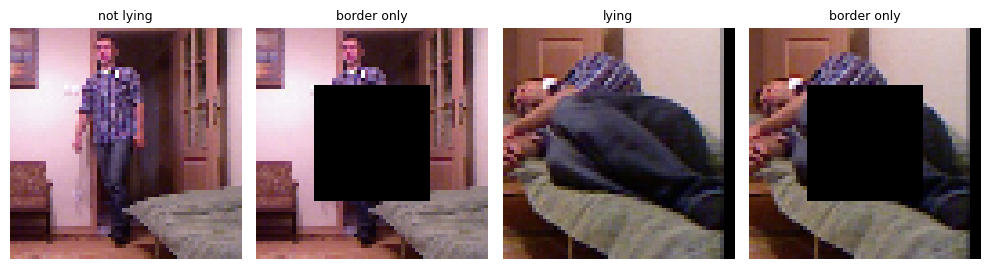

In [5]:
def masked_histograms(images, mask):
    out = []
    for image in images:
        h = cv2.calcHist([cv2.cvtColor(image, cv2.COLOR_RGB2HSV)], [0, 1, 2], mask, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel()
        out.append(h / h.sum())
    return np.array(out, dtype=np.float32)

centre = np.zeros((64, 64), np.uint8); centre[16:48, 16:48] = 1
border = 1 - centre
rows = []
for name, mask in [("centre only (person)", centre), ("border only (background)", border)]:
    p = cross_val_predict(KNeighborsClassifier(n_neighbors=5), masked_histograms(crops, mask), y, cv=cv)
    rows.append({"pixels used": name, "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro")})
print(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for k, phase in enumerate(["not lying", "lying"]):
    i = frames[frames.phase == phase].index[200]
    border_only = crops[i].copy(); border_only[centre == 1] = 0
    axes[2 * k].imshow(crops[i]); axes[2 * k].set_title(phase, fontsize=9)
    axes[2 * k + 1].imshow(border_only); axes[2 * k + 1].set_title("border only", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the **border alone** still gives **0.808** and the centre alone 0.821: much of the information comes from the background (floor, bed, wall), not from the person.
(The border still holds some body parts, e.g. the lying man's head and arms, so this is a strong hint, not a proof.)

## Step 5 — Three classifiers on the HSV 4 × 4 histograms

Same three classifiers and settings as notebooks 04 and 05. The SVM takes about 5 minutes here (2,048 numbers per frame).

In [6]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

X = colour_histograms(crops, "HSV", 4)
classifiers = {"KNN": KNeighborsClassifier(n_neighbors=5),
               "SVM": SVC(kernel="rbf"),
               "RF": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)}
pred, rows = {}, []
for name, clf in classifiers.items():
    t = time.time()
    pred[name] = cross_val_predict(clf, X, y, cv=cv)
    rows.append({"classifier": name, "frame accuracy": accuracy_score(y, pred[name]),
                 "macro F1": f1_score(y, pred[name], average="macro"), "time (s)": time.time() - t})
frame_scores = pd.DataFrame(rows).round(3)
frame_scores

,classifier,frame accuracy,macro F1,time (s)
0,KNN,0.883,0.834,2.569
1,SVM,0.886,0.834,61.320
2,RF,0.896,0.842,11.420


💡 **Interpretation:** colour gives the **best frame scores so far**: RF **0.896** (macro F1 0.842), better than LBP (0.867) and HOG (0.859).
But step 4 showed why: the same few rooms appear in training and test, so "floor-coloured crop" ≈ "lying". This would not transfer to a new room.

## Step 6 — Which postures are confused? (best classifier)

best: RF
              precision    recall  f1-score   support

   not lying       0.92      0.97      0.95      7054
     falling       0.72      0.68      0.70      1717
       lying       0.94      0.83      0.88      2256

    accuracy                           0.90     11027
   macro avg       0.86      0.83      0.84     11027
weighted avg       0.89      0.90      0.89     11027



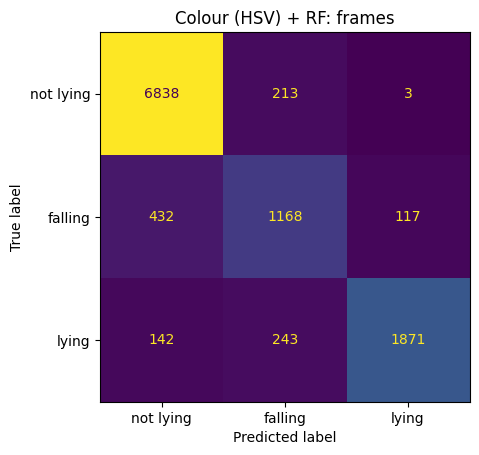

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = frame_scores.sort_values("macro F1").classifier.iloc[-1]
names = [PHASES[k] for k in (-1, 0, 1)]
print("best:", best)
print(classification_report(y, pred[best], target_names=names))
ConfusionMatrixDisplay.from_predictions(y, pred[best], display_labels=names, colorbar=False)
plt.title(f"Colour (HSV) + {best}: frames"); plt.show()

💡 **Interpretation:** *not lying* (F1 0.95) and *lying* (0.88) are very good; *falling* stays the hardest (0.70) and is mostly confused with *not lying* (432 frames):
at the start of a fall the crop still shows the same wall as when standing.

## Step 7 — From frames to the whole video: fall or no fall?

Same decision as notebooks 04 and 05: the **share** of each video's frames in each posture → logistic regression, same 5 video groups.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score

def video_decision(frame_pred):
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    video_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return share, y_video, cross_val_predict(model, share, y_video, cv=video_cv)

rows, video_pred = [], {}
for name in classifiers:
    share, y_video, video_pred[name] = video_decision(pred[name])
    rows.append({"classifier": name, "video accuracy": accuracy_score(y_video, video_pred[name]),
                 "recall (falls)": recall_score(y_video, video_pred[name]),
                 "precision (falls)": precision_score(y_video, video_pred[name])})
video_scores = pd.DataFrame(rows).round(3)
share, y_video, _ = video_decision(pred[best])
print(share.groupby(y_video).mean().rename(index={0: "ADL videos", 1: "fall videos"}).round(2))
video_scores

             share not lying  share falling  share lying
ADL videos              0.81           0.08         0.11
fall videos             0.40           0.33         0.28


,classifier,video accuracy,recall (falls),precision (falls)
0,KNN,0.800,0.767,0.767
1,SVM,0.843,0.833,0.806
2,RF,0.800,0.767,0.767


💡 **Interpretation:** with RF, ADL videos get **8%** of frames predicted *falling* vs **33%** for fall videos (HOG + KNN: 11% vs 35%).
Videos: **0.843 with SVM** (25 of 30 falls caught), 0.800 with KNN and RF: close to HOG + KNN (0.857).

## Step 8 — Which videos are wrong?

In [9]:
length = labels.groupby("video").size()
wrong_videos = share.index[video_pred[best] != y_video]
print(f"Colour + {best}: {len(wrong_videos)} wrong videos")
print(pd.DataFrame({"frames in video": length[wrong_videos], "share lying": share.loc[wrong_videos, "share lying"].round(2),
                    "share falling": share.loc[wrong_videos, "share falling"].round(2)}))
hog_wrong = {"fall-01", "fall-03", "fall-05", "fall-07", "fall-09", "adl-31", "adl-32", "adl-33", "adl-34", "adl-35"}  # notebook 04
print("\nalso wrong with HOG + KNN:", sorted(hog_wrong & set(wrong_videos)))

Colour + RF: 14 wrong videos
         frames in video  share lying  share falling
video                                               
adl-30               369         0.41           0.20
adl-31               250         0.32           0.44
adl-32               200         0.38           0.21
adl-33               200         0.22           0.27
adl-34               191         0.41           0.52
adl-35               280         0.35           0.45
adl-40               286         0.23           0.28
fall-01              160         0.31           0.12
fall-03              215         0.18           0.10
fall-07              156         0.13           0.25
fall-09              185         0.19           0.11
fall-13               85         0.15           0.27
fall-21               55         0.00           0.38
fall-27               92         0.00           0.37

also wrong with HOG + KNN: ['adl-31', 'adl-32', 'adl-33', 'adl-34', 'adl-35', 'fall-01', 'fall-03', 'fall-07', 'fall-09']


💡 **Interpretation:** **14 wrong videos** with RF (the best on frames), 9 of them already wrong with HOG: long falls (01, 03, 07, 09) and people lying down on purpose (adl-31…35).
New: the short falls **fall-21 and fall-27** have **0 frames** predicted *lying*, so they look like ADLs to the video decision.

## Step 9 — Save the scores and the frame predictions for the benchmark (notebook 08)

In [10]:
RESULTS = PROC / "results_traditional.csv"
scores = frame_scores.drop(columns="time (s)").merge(video_scores, on="classifier")
scores.insert(0, "descriptor", "Colour (HSV)")
old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame()
if len(old):
    old = old[old.descriptor != "Colour (HSV)"]
table = pd.concat([old, scores], ignore_index=True)
table.to_csv(RESULTS, index=False)
preds = frames[["video", "frame", "frame_label"]].assign(**{name: pred[name] for name in classifiers})
preds.to_csv(PROC / "predictions_colour.csv", index=False)   # every frame's predicted posture, for notebook 08
table

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,"SIFT (dense, BoVW)",KNN,0.839,0.771,0.757,0.667,0.741
1,"SIFT (dense, BoVW)",SVM,0.866,0.799,0.743,0.667,0.714
2,"SIFT (dense, BoVW)",RF,0.858,0.790,0.786,0.733,0.759
3,HOG,KNN,0.859,0.799,0.857,0.833,0.833
4,HOG,SVM,0.859,0.795,0.800,0.733,0.786
5,HOG,RF,0.855,0.770,0.829,0.767,0.821
6,LBP,KNN,0.867,0.816,0.771,0.767,0.719
7,LBP,SVM,0.873,0.810,0.757,0.733,0.710
8,LBP,RF,0.866,0.796,0.786,0.733,0.759
9,Colour (HSV),KNN,0.883,0.834,0.800,0.767,0.767


💡 **Interpretation:** the 3 colour rows are saved with the other descriptors' rows: colour gives the **best frames** (RF 0.896), but the **best videos** still come from HOG + KNN (0.857), just ahead of colour + SVM (0.843).
The predicted posture of every frame is also saved (`predictions_colour.csv`), so notebook 08 can compare the methods video by video.

## What we learned

1. A **colour histogram** counts how many pixels have each colour; **HSV** (hue, saturation, brightness) works better than RGB because it separates colour from lighting.
2. With a **4 × 4 grid**, colour gives the **best frame scores of the 3 descriptors** (RF 0.896, macro F1 0.842).
3. **But colour mostly recognises the surroundings:** the background alone (crop border) already gives 0.808. A lying person's crop is full of floor or bed, a standing person's crop is full of wall.
   It works here because the **same rooms** appear in training and test; in a new room it would likely fail. HOG and LBP describe the person's shape and texture, which transfers better.
4. **Videos:** best 0.843 (SVM), still below HOG + KNN (0.857). The same hard cases come back (long falls, lying down on purpose).
5. **Lesson for the report:** a high score is not enough; we must check **what** the model uses. Colour is a good example of a "shortcut" that a dataset with few rooms makes easy.

**Next notebook (07):** **SIFT** keypoints with a *bag of visual words*, the last traditional descriptor.